# Ансамблевые модели

Ансамблевые методы — это подход в машинном обучении, при котором несколько моделей (обычно слабых учеников) объединяются, чтобы создать более сильную предсказательную модель. Основная идея ансамблей — улучшение качества модели за счёт уменьшения:

 - **Смещения (bias)** — особенно с помощью бустинга
 - **Дисперсии (variance)** — особенно с помощью бэггинга
 - **Переобучения** — за счёт комбинации моделей


Примеры ансамблевых методов:

 - Бэггинг (Bagging)
 - Случайный лес (Random Forest)
 - Бустинг (Boosting)
 - XGBoost, LightGBM, CatBoost
 - Стэкинг (Stacking)

| Компонент                | Что означает                                     | Когда большая?                              |
| ------------------------ | ------------------------------------------------ | ------------------------------------------- |
| **Смещение (bias)**      | Насколько модель в среднем **далека от истины**  | Когда модель слишком простая (underfitting) |
| **Дисперсия (variance)** | Насколько модель **меняется от данных к данным** | Когда модель слишком сложная (overfitting)  |


## Визуализация: Смещение и Разброс



Ниже показаны иллюстрации различий между высокой/низкой дисперсией и высоким/низким смещением.
Представим стрельбу по мишени:
 - Высокое смещение — предсказания отклонены от цели.
 - Высокая дисперсия — предсказания разбросаны.

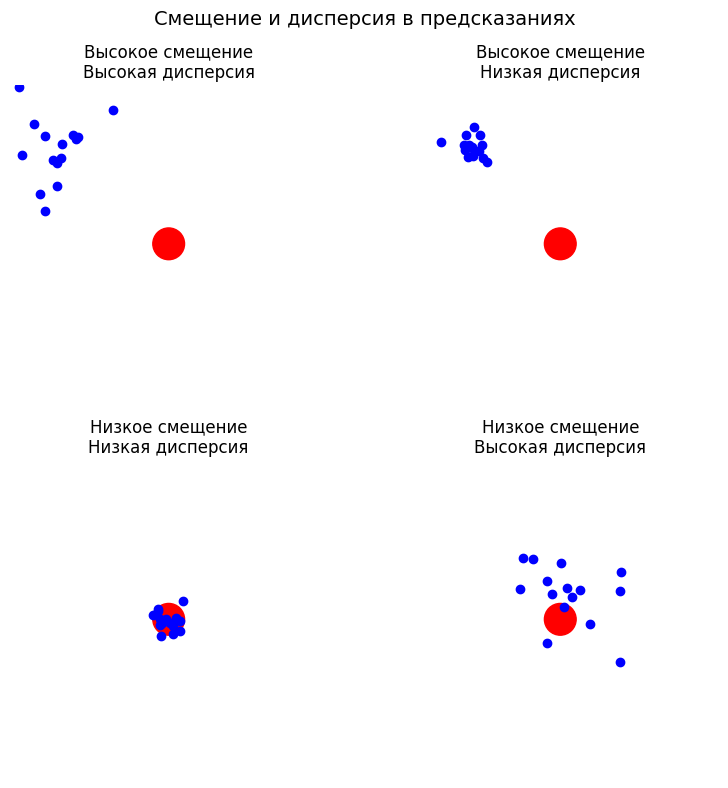

In [1]:
import matplotlib.pyplot as plt
import numpy as np

def draw_bias_variance(ax, points, title):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.set_aspect('equal')
    ax.add_patch(plt.Circle((5, 5), 0.5, color='red'))  # цель
    ax.scatter(points[:, 0], points[:, 1], color='blue')
    ax.set_title(title)
    ax.axis('off')

fig, axs = plt.subplots(2, 2, figsize=(8, 8))

np.random.seed(0)

draw_bias_variance(axs[0, 1], np.random.normal(loc=[2, 8], scale=0.3, size=(15, 2)), "Высокое смещение\nНизкая дисперсия")
draw_bias_variance(axs[0, 0], np.random.normal(loc=[2, 8], scale=1.0, size=(15, 2)), "Высокое смещение\nВысокая дисперсия")
draw_bias_variance(axs[1, 0], np.random.normal(loc=[5, 5], scale=0.3, size=(15, 2)), "Низкое смещение\nНизкая дисперсия")
draw_bias_variance(axs[1, 1], np.random.normal(loc=[5, 5], scale=1.0, size=(15, 2)), "Низкое смещение\nВысокая дисперсия")

plt.suptitle("Смещение и дисперсия в предсказаниях", fontsize=14)
plt.tight_layout()
plt.show()

Эти картинки помогают интуитивно понять:
 - Бэггинг уменьшает дисперсию, сглаживая предсказания.
 - Бустинг уменьшает смещение, фокусируясь на трудных объектах.
 - Хороший ансамбль стремится к предсказаниям с низким смещением и низкой дисперсией.



 Представим, что у нас есть $M$ моделей $h_1(x), h_2(x), \dots, h_M(x)$. Предсказание ансамбля:
 $$
 \hat{y}_{ensemble}(x) = \frac{1}{M} \sum_{m=1}^M h_m(x)
 $$

 Рассмотрим среднеквадратичную ошибку ансамбля:
 $$
 \text{MSE} = \mathbb{E}[(\hat{y}_{ensemble}(x) - y)^2]
 $$

Пусть каждая модель имеет ошибку $\varepsilon_i(x) = h_i(x) - y$ с одинаковой дисперсией $\sigma^2$ и попарной корреляцией $\rho$:

 Тогда дисперсия ошибки ансамбля:
 $$
 Var(\hat{y}_{ensemble}) = \frac{1}{M^2} \left( M \cdot \sigma^2 + M(M - 1) \cdot \rho \cdot \sigma^2 \right)
 $$
 $$
 = \sigma^2 \cdot \left( \frac{1 - \rho}{M} + \rho \right)
 $$

Выводы:
 - Чем **больше моделей** $M$, тем **меньше дисперсия** при фиксированном $\rho$.
 - При **$\rho = 0$** (некоррелированные ошибки):
   $$
   Var(\hat{y}) = \frac{\sigma^2}{M}
   $$
 - При **$\rho = 1$** (полностью коррелированные ошибки):
   $$
   Var(\hat{y}) = \sigma^2
   $$
 - Чем **меньше корреляция ошибок**, тем **больше выигрыш** от ансамблирования.

Интуитивно:
 Если модели делают разные ошибки, они могут «взаимно компенсироваться», и среднее становится более точным предсказанием.

 Вот почему в ансамблях важно **разнообразие моделей**:
 - Бэггинг достигает этого через бутстрап и случайность в деревьях
 - Случайный лес — дополнительно случайный выбор признаков
 - Стэкинг — объединение разных алгоритмов

Поэтому **ансамбли из одинаковых и одинаково ошибающихся моделей бесполезны** — нужен именно декоррелированный шум

## Бэггинг (Bagging)

1. На первом шаге из исходного набора данных $D$ формируется $B$ новых выборок $D_1, D_2, ..., D_B$ с помощью **бутстрэпа** — метода случайного выбора объектов с возвращением.

2. На каждой из этих бутстрэп-выборок независимо обучается своя базовая модель $h_b(x)$.

3. Итоговый прогноз для нового объекта $x$ получается путём усреднения предсказаний всех моделей ансамбля:

 $$
 \hat{y}_{bag}(x) = \frac{1}{B} \sum_{b=1}^B h_b(x)
 $$

 За счет бутстрэпа и усреднения предсказаний бэггинг снижает дисперсию моделей

## Случайный лес (Random Forest)

Случайный лес = бэггинг + случайный подвыбор признаков при построении деревьев.

**Основные принципы**:

- Каждое дерево строится на своей бутстрап-выборке
- При каждом разбиении узла рассматривается случайное подмножество признаков размером `m_try` из всех `p` доступных

Это обеспечивает **декорреляцию деревьев** → снижает дисперсию ансамбля.

## Измеряем смещение и разброс

На реальных данных истинная зависимость $f(x)$ неизвестна, поэтому смещение и разброс честно посчитать нельзя. Сделаем эксперимент на синтетике, где $f(x)$ и шум известны:

1. много раз (60) генерируем новую обучающую выборку и обучаем на ней модель;
2. в фиксированных тестовых точках смотрим на 60 прогнозов;
3. **смещение²** = (средний прогноз − $f(x)$)², **разброс** = дисперсия прогнозов, **шум** $\sigma^2$ известен заранее.

Сравним одиночное дерево и бэггинг из 25 таких же деревьев при разной глубине.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor

rng = np.random.default_rng(0)

def f_true(x):
    return np.sin(x[:, 0]) + 0.5 * np.cos(2 * x[:, 1]) + 0.3 * x[:, 0] * x[:, 1] / 5

sigma = 0.5                                   # стандартное отклонение шума, σ² = 0.25
X_test_syn = rng.uniform(0, 6, (400, 2))      # фиксированные тестовые точки
f_test_syn = f_true(X_test_syn)

n_rounds, n_train = 60, 300
rows = []
for depth in [1, 2, 3, 4, 6, 8, 10, 15]:
    p_tree = np.zeros((n_rounds, len(X_test_syn)))
    p_bag = np.zeros((n_rounds, len(X_test_syn)))
    for r in range(n_rounds):
        X_tr = rng.uniform(0, 6, (n_train, 2))
        y_tr = f_true(X_tr) + rng.normal(0, sigma, n_train)
        p_tree[r] = DecisionTreeRegressor(max_depth=depth, random_state=r).fit(X_tr, y_tr).predict(X_test_syn)
        bag = BaggingRegressor(DecisionTreeRegressor(max_depth=depth), n_estimators=25, random_state=r)
        p_bag[r] = bag.fit(X_tr, y_tr).predict(X_test_syn)
    for name, p in [('одно дерево', p_tree), ('бэггинг', p_bag)]:
        bias2 = ((p.mean(axis=0) - f_test_syn) ** 2).mean()
        var = p.var(axis=0).mean()
        rows.append({'depth': depth, 'model': name, 'bias2': bias2, 'variance': var, 'bias2+var+noise': bias2 + var + sigma ** 2})

bv = pd.DataFrame(rows)
bv.pivot(index='depth', columns='model', values=['bias2', 'variance', 'bias2+var+noise']).round(3)

bias2             variance             bias2+var+noise            
model бэггинг одно дерево  бэггинг одно дерево         бэггинг одно дерево
depth                                                                     
1       0.301       0.313    0.024       0.048           0.575       0.611
2       0.145       0.155    0.022       0.053           0.416       0.458
3       0.078       0.083    0.035       0.091           0.363       0.424
4       0.044       0.046    0.040       0.108           0.334       0.404
6       0.017       0.015    0.055       0.158           0.322       0.424
8       0.011       0.010    0.070       0.230           0.331       0.490
10      0.009       0.008    0.075       0.266           0.334       0.524
15      0.009       0.008    0.081       0.295           0.340       0.553

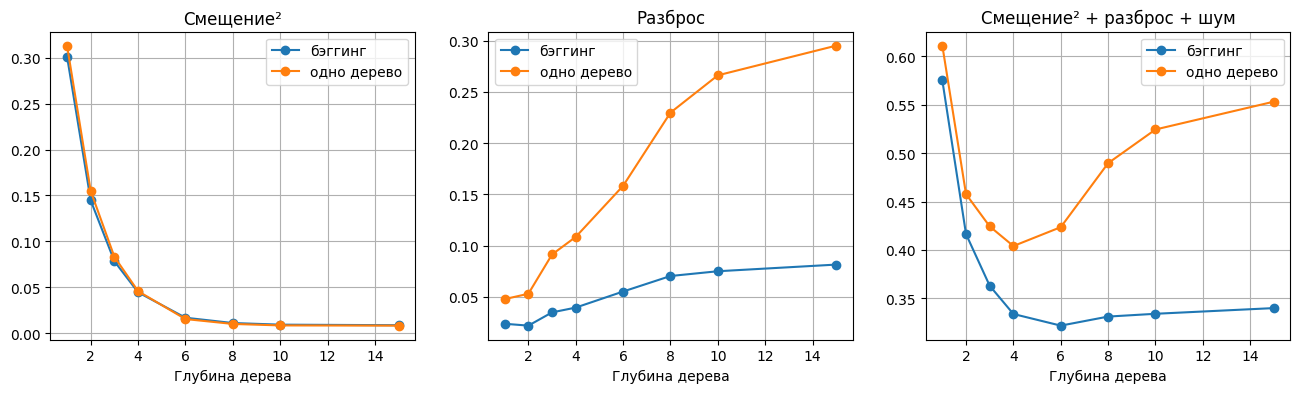

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ['bias2', 'variance', 'bias2+var+noise'], ['Смещение²', 'Разброс', 'Смещение² + разброс + шум']):
    for name, part in bv.groupby('model'):
        ax.plot(part['depth'], part[col], marker='o', label=name)
    ax.set_title(title); ax.set_xlabel('Глубина дерева'); ax.grid(); ax.legend()
plt.show()

**Вывод.** С ростом глубины смещение² одиночного дерева падает с 0,31 до 0,01, а разброс растет с 0,05 до 0,30. Минимум суммарной ошибки (0,40) достигается на глубине 4. У бэггинга смещение² почти такое же, а разброс в 2–4 раза меньше (на глубине 15: 0,08 против 0,30), поэтому суммарная ошибка ниже (минимум 0,32 на глубине 6), и оптимум сдвигается к более глубоким деревьям. Разброс бэггинга не нулевой: деревья обучены на пересекающихся выборках и коррелируют. Шум (0,25) не убирается никаким ансамблем.

# Практика

Рассмотрим датасет, в котором собраны данные о более чем 22 тыс. объектов жилой недвижимости в Москве и МО.

Разведочный анализ и линейную регрессию на этих данных мы уже делали, поэтому здесь только подготовка данных, а дальше сразу ансамбли.

## Подготовка данных

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [5]:
FLATS = 'https://github.com/evgpat/ml_basics_course/raw/main/datasets/flats.csv'

In [6]:
# Загрузим датасет
df = pd.read_csv(FLATS)

In [7]:
df.head()

,Price,Apartment type,Metro station,Minutes to metro,Region,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors,Renovation
0,6300000.0,Secondary,Опалиха,6.0,Moscow region,1.0,30.6,11.1,8.5,25.0,25,Cosmetic
1,9000000.0,Secondary,Павшино,2.0,Moscow region,1.0,49.2,20.0,10.0,6.0,15,European-style renovation
2,11090000.0,Secondary,Мякинино,14.0,Moscow region,1.0,44.7,16.2,13.1,10.0,25,Cosmetic
3,8300000.0,Secondary,Строгино,8.0,Moscow region,1.0,35.1,16.0,11.0,12.0,33,European-style renovation
4,6450000.0,Secondary,Опалиха,6.0,Moscow region,1.0,37.7,15.2,4.0,5.0,5,Without renovation


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22676 entries, 0 to 22675
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Price             22676 non-null  float64
 1   Apartment type    22676 non-null  object 
 2   Metro station     22676 non-null  object 
 3   Minutes to metro  22676 non-null  float64
 4   Region            22676 non-null  object 
 5   Number of rooms   22676 non-null  float64
 6   Area              22676 non-null  float64
 7   Living area       22676 non-null  float64
 8   Kitchen area      22676 non-null  float64
 9   Floor             22676 non-null  float64
 10  Number of floors  22676 non-null  int64  
 11  Renovation        22676 non-null  object 
dtypes: float64(7), int64(1), object(4)
memory usage: 2.1+ MB


Из прошлого разбора нужна одна деталь: некоторые названия станций метро начинаются с пробела, из-за этого, например, «Охотный ряд» и « Охотный ряд» считались бы разными станциями. Исправляем.

In [9]:
print('Станций до очистки:', df['Metro station'].nunique())
df['Metro station'] = df['Metro station'].str.strip()
print('Станций после очистки:', df['Metro station'].nunique())

Станций до очистки: 547
Станций после очистки: 317


Кодируем категориальные признаки: one-hot для типа квартиры, региона и ремонта, а станцию метро заменим средней ценой по станции (считаем только по обучающей выборке).

In [10]:
df_with_cat = pd.get_dummies(df, columns =['Apartment type', 'Region', 'Renovation'])
X = df_with_cat.drop('Price', axis=1)
y = df_with_cat['Price']

In [11]:
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.25, random_state=42)

In [12]:
train_x = train_x.copy()
test_x = test_x.copy()

mean_enc = pd.concat([train_x, train_y], axis=1).groupby('Metro station')['Price'].mean()
train_x['metro_m_enc'] = train_x['Metro station'].map(mean_enc)
test_x['metro_m_enc'] = test_x['Metro station'].map(mean_enc)
train_x.head()

,Metro station,Minutes to metro,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors,Apartment type_New building,Apartment type_Secondary,Region_Moscow,Region_Moscow region,Renovation_Cosmetic,Renovation_Designer,Renovation_European-style renovation,Renovation_Without renovation,metro_m_enc
13300,Красногвардейская,5.0,3.0,83.0,44.1,13.5,11.0,20,True,False,False,True,True,False,False,False,6.176100e+06
11436,Преображенская площадь,12.0,0.0,31.5,18.1,9.2,4.0,4,False,True,True,False,False,False,True,False,1.343580e+07
7228,Охотный ряд,5.0,2.0,66.0,37.0,8.0,3.0,8,False,True,True,False,False,False,True,False,2.789732e+08
9239,Нагорная,14.0,3.0,71.7,52.4,8.1,4.0,5,False,True,True,False,False,False,True,False,2.432518e+07
10381,Кропоткинская,11.0,4.0,235.0,170.0,35.0,5.0,8,False,True,True,False,False,True,False,False,2.259776e+08


В тесте есть станция, которой нет в обучающей выборке (у нее среднее не определено). Заполним ее средним по обучающей выборке и уберем название станции.

In [13]:
print('Пропусков в metro_m_enc на тесте:', test_x['metro_m_enc'].isnull().sum())
test_x['metro_m_enc'] = test_x['metro_m_enc'].fillna(train_x['metro_m_enc'].mean())
train_x = train_x.drop(['Metro station'], axis=1)
test_x = test_x.drop(['Metro station'], axis=1)

Пропусков в metro_m_enc на тесте: 1


## Дерево решений и случайный лес

In [14]:
from sklearn.tree import DecisionTreeRegressor

In [15]:
dt = DecisionTreeRegressor()
dt.fit(train_x, train_y)

DecisionTreeRegressor()

In [16]:
pred_train_tree = dt.predict(train_x)
pred_test_tree = dt.predict(test_x)
print(f'RMSE train: {round(root_mean_squared_error(train_y, pred_train_tree), 5)}')
print(f'MAE train: {round(mean_absolute_error(train_y, pred_train_tree), 5)}')
print(f'R2 train: {round(r2_score(train_y, pred_train_tree), 5)}')
print(f'RMSE: {round(root_mean_squared_error(test_y, pred_test_tree), 5)}')
print(f'MAE: {round(mean_absolute_error(test_y, pred_test_tree), 5)}')
print(f'R2: {round(r2_score(test_y, pred_test_tree), 5)}')

RMSE train: 364088.47151
MAE train: 35891.10099
R2 train: 0.99998
RMSE: 38753640.91877
MAE: 8102638.16086
R2: 0.76921


In [17]:
dt2 = DecisionTreeRegressor(max_depth=5)
dt2.fit(train_x, train_y)

DecisionTreeRegressor(max_depth=5)

In [18]:
pred_train_tree2 = dt2.predict(train_x)
pred_test_tree2 = dt2.predict(test_x)
print(f'RMSE train: {round(root_mean_squared_error(train_y, pred_train_tree2), 5)}')
print(f'MAE train: {round(mean_absolute_error(train_y, pred_train_tree2), 5)}')
print(f'R2 train: {round(r2_score(train_y, pred_train_tree2), 5)}')
print(f'RMSE: {round(root_mean_squared_error(test_y, pred_test_tree2), 5)}')
print(f'MAE: {round(mean_absolute_error(test_y, pred_test_tree2), 5)}')
print(f'R2: {round(r2_score(test_y, pred_test_tree2), 5)}')

RMSE train: 33092496.86363
MAE train: 10827234.15811
R2 train: 0.84304
RMSE: 37772318.70559
MAE: 11859351.97097
R2: 0.78075


In [19]:
from sklearn.ensemble import RandomForestRegressor

In [20]:
rf = RandomForestRegressor(random_state=42, max_depth=15)
rf.fit(train_x, train_y)

RandomForestRegressor(max_depth=15, random_state=42)

In [21]:
pred_train_rf = rf.predict(train_x)
pred_test_rf = rf.predict(test_x)
print(f'RMSE train: {round(root_mean_squared_error(train_y, pred_train_rf), 5)}')
print(f'MAE train: {round(mean_absolute_error(train_y, pred_train_rf), 5)}')
print(f'R2 train: {round(r2_score(train_y, pred_train_rf), 5)}')
print(f'RMSE: {round(root_mean_squared_error(test_y, pred_test_rf), 5)}')
print(f'MAE: {round(mean_absolute_error(test_y, pred_test_rf), 5)}')
print(f'R2: {round(r2_score(test_y, pred_test_rf), 5)}')

RMSE train: 12817199.15237
MAE train: 3013470.01757
R2 train: 0.97645
RMSE: 28679950.19798
MAE: 7261118.42098
R2: 0.8736


## Бэггинг своими руками

Сначала посмотрим, что такое бутстреп-выборка и какая доля объектов в нее попадает.

In [22]:
pd.options.display.float_format = '{:,.3f}'.format   # три знака, чтобы различия в R2 были видны

rng = np.random.default_rng(1)
n = len(train_x)
idx = rng.integers(0, n, n)          # бутстреп: n индексов, выбранных с возвращением
print('Размер обучающей выборки:', n)
print('Уникальных объектов в бутстреп-выборке:', len(np.unique(idx)))
print('Доля уникальных:', round(len(np.unique(idx)) / n, 4), '| теоретически 1 - 1/e =', round(1 - np.exp(-1), 4))

for m in [10, 100, 1000, n]:
    print(f'n = {m:>6}: доля объектов, ни разу не выбранных = {(1 - 1 / m) ** m:.4f}')

Размер обучающей выборки: 17007
Уникальных объектов в бутстреп-выборке: 10758
Доля уникальных: 0.6326 | теоретически 1 - 1/e = 0.6321
n =     10: доля объектов, ни разу не выбранных = 0.3487
n =    100: доля объектов, ни разу не выбранных = 0.3660
n =   1000: доля объектов, ни разу не выбранных = 0.3677
n =  17007: доля объектов, ни разу не выбранных = 0.3679


**Вывод.** В бутстреп-выборку попадает около 63,2% уникальных объектов (10 758 из 17 007), остальные ≈ 36,8% для этого дерева out-of-bag. Уже при n порядка 1000 значение $(1-1/n)^n$ практически совпадает с пределом $e^{-1}$.

Теперь сам бэггинг: обучаем много деревьев на бутстреп-выборках и усредняем их прогнозы. Одно дерево без ограничения глубины для сравнения уже обучено выше (`dt`).

In [23]:
from sklearn.base import clone

def bagging_predictions(base_model, n_estimators, X_tr, y_tr, X_te, seed=0):
    # возвращает матрицу прогнозов размера (n_estimators, число объектов в X_te)
    rng = np.random.default_rng(seed)
    all_preds = []
    for _ in range(n_estimators):
        idx = rng.integers(0, len(X_tr), len(X_tr))
        model = clone(base_model).fit(X_tr.iloc[idx], y_tr.iloc[idx])
        all_preds.append(model.predict(X_te))
    return np.array(all_preds)

preds = bagging_predictions(DecisionTreeRegressor(random_state=0), 50, train_x, train_y, test_x)
print('Одно дерево из бэггинга: R2 =', round(r2_score(test_y, preds[0]), 4), ' RMSE =', round(root_mean_squared_error(test_y, preds[0])))
print('Среднее 50 деревьев:      R2 =', round(r2_score(test_y, preds.mean(axis=0)), 4), ' RMSE =', round(root_mean_squared_error(test_y, preds.mean(axis=0))))
print('Дерево на всей выборке:   R2 =', round(r2_score(test_y, pred_test_tree), 4), ' RMSE =', round(root_mean_squared_error(test_y, pred_test_tree)))

Одно дерево из бэггинга: R2 = 0.7405  RMSE = 41095117
Среднее 50 деревьев:      R2 = 0.8669  RMSE = 29434118
Дерево на всей выборке:   R2 = 0.7692  RMSE = 38753641


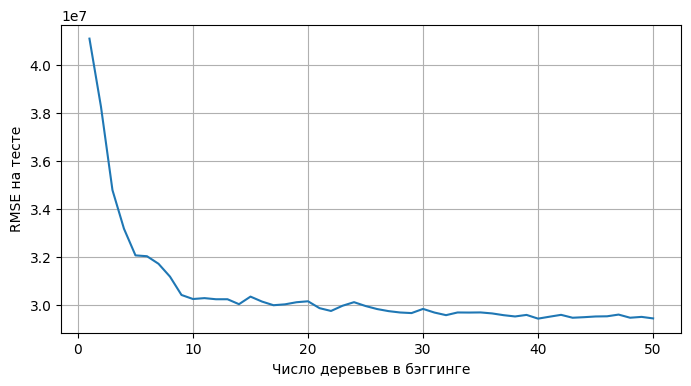

In [24]:
# как меняется ошибка при добавлении деревьев в ансамбль
ks = np.arange(1, 51)
rmse_k = [root_mean_squared_error(test_y, preds[:k].mean(axis=0)) for k in ks]
plt.figure(figsize=(8, 4))
plt.plot(ks, rmse_k)
plt.xlabel('Число деревьев в бэггинге'); plt.ylabel('RMSE на тесте'); plt.grid()
plt.show()

**Вывод.** Дерево на одной бутстреп-выборке хуже дерева на всей обучающей выборке (R² 0,74 против 0,77), но среднее 50 таких деревьев дает R² 0,87 и RMSE 29,4 млн против 38,8 млн у одного дерева. Основной выигрыш получается на первых 10 деревьях, дальше кривая выходит на плато около 30 млн.

То же самое делает готовый `BaggingRegressor`. Попробуем разные базовые модели: бэггинг должен помогать неустойчивым моделям (глубокое дерево) и почти не помогать устойчивым (линейная регрессия).

In [25]:
from sklearn.ensemble import BaggingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline

results = {}   # сюда будем собирать итоговые метрики на тесте

def evaluate(name, model, fit=True):
    if fit:
        model.fit(train_x, train_y)
    pred = model.predict(test_x)
    results[name] = {'R2': r2_score(test_y, pred), 'RMSE, млн': root_mean_squared_error(test_y, pred) / 1e6,
                     'MAE, млн': mean_absolute_error(test_y, pred) / 1e6}
    return pd.Series(results[name])

bases = {
    'Дерево без ограничений': DecisionTreeRegressor(random_state=0),
    'Линейная регрессия': LinearRegression(),
    'kNN (k=10, стандартизация)': make_pipeline(StandardScaler(), KNeighborsRegressor(10)),
}
table = {}
for name, base in bases.items():
    table[name] = evaluate(name, clone(base))
    table['Бэггинг: ' + name] = evaluate('Бэггинг: ' + name, BaggingRegressor(base, n_estimators=30, random_state=0, n_jobs=-1))
pd.DataFrame(table).T

,R2,"RMSE, млн","MAE, млн"
Дерево без ограничений,0.773,38.442,8.172
Бэггинг: Дерево без ограничений,0.874,28.617,7.269
Линейная регрессия,0.703,43.989,17.843
Бэггинг: Линейная регрессия,0.703,43.980,17.829
"kNN (k=10, стандартизация)",0.734,41.607,10.951
"Бэггинг: kNN (k=10, стандартизация)",0.738,41.263,10.831


**Вывод.** Бэггинг сильно помогает неустойчивому глубокому дереву (R² 0,773 → 0,874, RMSE 38,4 → 28,6 млн) и почти ничего не дает устойчивым моделям: линейная регрессия 0,703 → 0,703, kNN 0,734 → 0,738. У устойчивой модели разброс и так мал, усреднять нечего.

Для kNN возьмем $k = 1$, $10$ и $30$ и сравните качество одной модели и бэггинга из 30 таких моделей. При каком $k$ бэггинг помогает сильнее и почему?

In [26]:
rows = {}
for k in [1, 10, 30]:
    base = make_pipeline(StandardScaler(), KNeighborsRegressor(k))
    single = clone(base).fit(train_x, train_y).predict(test_x)
    bag = BaggingRegressor(base, n_estimators=30, random_state=0, n_jobs=-1).fit(train_x, train_y).predict(test_x)
    rows[f'k={k}'] = {'R2 одна модель': r2_score(test_y, single), 'R2 бэггинг': r2_score(test_y, bag)}
pd.DataFrame(rows).T

,R2 одна модель,R2 бэггинг
k=1,0.705,0.750
k=10,0.734,0.738
k=30,0.717,0.719


**Вывод.** Выигрыш от бэггинга тем больше, чем неустойчивее базовая модель. При k=1 (один ближайший сосед, ответ целиком зависит от того, какие объекты попали в выборку) R² растет с 0,705 до 0,750. При k=10 прирост уже почти нулевой (0,734 → 0,738), при k=30 его практически нет (0,717 → 0,719): усреднение по 30 соседям уже само сглаживает шум, и разброс у такой модели небольшой. Бэггинг уменьшает разброс, но не смещение, поэтому kNN с любым k остается заметно хуже леса (0,87).

## Случайный лес

Случайный лес отличается от бэггинга деревьев одним параметром: на каждом сплите рассматривается только часть признаков (`max_features`). В `scikit-learn` значения по умолчанию разные: у `RandomForestClassifier` это `'sqrt'`, а у `RandomForestRegressor` это `1.0`, то есть все признаки. Получается, что регрессор из коробки работает как обычный бэггинг.

In [27]:
rows = []
for mf in [1.0, 0.5, 1 / 3, 0.2]:
    m = RandomForestRegressor(random_state=42, max_depth=15, max_features=mf, n_jobs=-1).fit(train_x, train_y)
    rows.append({'max_features': round(mf, 2),
                 'R2 train': r2_score(train_y, m.predict(train_x)),
                 'R2 test': r2_score(test_y, m.predict(test_x)),
                 'RMSE test, млн': root_mean_squared_error(test_y, m.predict(test_x)) / 1e6})
pd.DataFrame(rows)

,max_features,R2 train,R2 test,"RMSE test, млн"
0,1.000,0.976,0.874,28.680
1,0.500,0.977,0.854,30.860
2,0.330,0.976,0.846,31.693
3,0.200,0.975,0.832,33.097


**Вывод.** На этих данных лучшее качество при `max_features=1.0` (R² на тесте 0,874), а при уменьшении доли признаков падает до 0,832. Вероятная причина: несколько признаков (площадь, метро) намного сильнее остальных, и когда на многих сплитах они недоступны, деревья слабеют, а выигрыш от декорреляции не компенсирует потери. Правило «1/3 для регрессии» остается лишь отправной точкой: параметр подбирают. R² на обучающей выборке почти не меняется (0,975–0,977), то есть переобучение деревьев по-прежнему сильное, а выигрыш от леса дает усреднение.

Число деревьев: смотрим на ошибку на тесте при росте `n_estimators`.

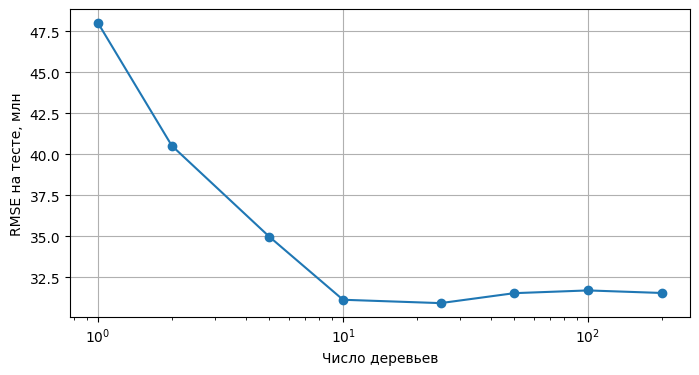

{1: 48.01,
 2: 40.52,
 5: 34.97,
 10: 31.12,
 25: 30.92,
 50: 31.53,
 100: 31.69,
 200: 31.54}

In [28]:
n_list = [1, 2, 5, 10, 25, 50, 100, 200]
rmse_n = []
for n_est in n_list:
    m = RandomForestRegressor(n_estimators=n_est, random_state=42, max_depth=15, max_features=1 / 3, n_jobs=-1).fit(train_x, train_y)
    rmse_n.append(root_mean_squared_error(test_y, m.predict(test_x)) / 1e6)
plt.figure(figsize=(8, 4))
plt.plot(n_list, rmse_n, marker='o')
plt.xscale('log'); plt.xlabel('Число деревьев'); plt.ylabel('RMSE на тесте, млн'); plt.grid()
plt.show()
dict(zip(n_list, [round(float(v), 2) for v in rmse_n]))

**Вывод.** Ошибка быстро падает до 10 деревьев (48,0 → 31,1 млн), затем почти не меняется (25 деревьев: 30,9; 200 деревьев: 31,5). Добавлять деревья дальше можно, но время обучения растет линейно, а выигрыш пренебрежимо мал. Небольшие колебания (например, 50 деревьев хуже 25) укладываются в случайность.

**Out-of-bag оценка.** Каждое дерево не видело около 37% объектов. Для каждого объекта усредняем прогнозы только тех деревьев, которые его не видели, и считаем качество. Получаем оценку без отдельной валидационной выборки (`oob_score=True`, по умолчанию выключено).

In [29]:
rf_oob = RandomForestRegressor(n_estimators=200, random_state=42, max_depth=15, max_features=1 / 3, oob_score=True, n_jobs=-1)
rf_oob.fit(train_x, train_y)
print('OOB R2 :', round(rf_oob.oob_score_, 4))
print('Test R2:', round(r2_score(test_y, rf_oob.predict(test_x)), 4))

OOB R2 : 0.8468
Test R2: 0.8472


**Вывод.** OOB R² (0,847) практически совпадает с R² на тесте (0,847), хотя тестовая выборка при обучении не использовалась. Значит, OOB позволяет оценить качество леса без отдельной валидации и экономит данные.

Посчитаем OOB R² и R² на тесте для леса из 10, 50 и 200 деревьев (глубина 15, `max_features=1/3`). Начиная с какого числа деревьев OOB-оценка близка к тестовой? (Для 10 деревьев `sklearn` предупредит, что у части объектов нет OOB-прогноза: они попали во все деревья.)

In [30]:
rows = {}
for n_est in [10, 50, 200]:
    m = RandomForestRegressor(n_estimators=n_est, random_state=42, max_depth=15, max_features=1 / 3, oob_score=True, n_jobs=-1).fit(train_x, train_y)
    rows[n_est] = {'OOB R2': m.oob_score_, 'Test R2': r2_score(test_y, m.predict(test_x))}
pd.DataFrame(rows).T

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,OOB R2,Test R2
10,0.796,0.851
50,0.843,0.847
200,0.847,0.847


**Вывод.** Для 10 деревьев OOB R² (0,796) заметно ниже теста (0,851). Причины две: у каждого объекта в среднем остается всего 3-4 «невидевших» его дерева, поэтому OOB-прогноз шумный; а примерно у 1% объектов (около 175) таких деревьев нет вообще, и sklearn подставляет им нулевой прогноз (отсюда предупреждение). С ростом числа деревьев OOB подтягивается к тесту: 0,843 при 50 и 0,847 при 200 (тест 0,847). Для OOB-оценки нужно достаточно много деревьев.

**Важность признаков.** Две версии:

- `feature_importances_` (impurity) считается по обучающей выборке: сколько неопределенности убрали сплиты по признаку;
- перестановочная важность (permutation): на сколько падает качество на отложенной выборке, если значения признака перемешать.

In [31]:
from sklearn.inspection import permutation_importance

rf15 = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=15, n_jobs=-1).fit(train_x, train_y)
sub = test_x.sample(2000, random_state=0)
pi = permutation_importance(rf15, sub, test_y.loc[sub.index], n_repeats=5, random_state=0, n_jobs=-1, scoring='r2')
imp = pd.DataFrame({'impurity': rf15.feature_importances_, 'permutation': pi.importances_mean}, index=train_x.columns)
imp.sort_values('permutation', ascending=False).head(8)

,impurity,permutation
Area,0.677,0.849
metro_m_enc,0.156,0.345
Living area,0.059,0.065
Floor,0.020,0.025
Number of floors,0.022,0.021
Kitchen area,0.020,0.015
Minutes to metro,0.029,0.015
Number of rooms,0.007,0.008


**Вывод.** Обе версии ставят на первые места площадь и метро (mean encoding), но разрыв разный: impurity-важность у площади 0,68, у метро 0,16, а перестановочная (падение R²) 0,85 и 0,35 соответственно. Перестановочная версия считается на отложенной выборке и не завышает признаки с множеством значений. Падения R² не обязаны суммироваться в единицу: признаки связаны, поэтому перемешивание одного затрагивает информацию в другом.

Подбор гиперпараметров. Сетка небольшая: каждая комбинация обучается 3 раза (`cv=3`).

In [32]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [10, 15, None],
    'max_features': [1.0, 0.5, 1 / 3],
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(n_estimators=100, random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

In [33]:
grid_search.fit(train_x, train_y)
print('Лучшие параметры:', grid_search.best_params_)
best_rf = grid_search.best_estimator_

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Лучшие параметры: {'max_depth': None, 'max_features': 0.5}


In [34]:
pred_train_rf = best_rf.predict(train_x)
pred_test_rf = best_rf.predict(test_x)

In [35]:
print(f'RMSE train: {round(root_mean_squared_error(train_y, pred_train_rf), 5)}')
print(f'MAE train: {round(mean_absolute_error(train_y, pred_train_rf), 5)}')
print(f'R2 train: {round(r2_score(train_y, pred_train_rf), 5)}')
print(f'RMSE: {round(root_mean_squared_error(test_y, pred_test_rf), 5)}')
print(f'MAE: {round(mean_absolute_error(test_y, pred_test_rf), 5)}')
print(f'R2: {round(r2_score(test_y, pred_test_rf), 5)}')

RMSE train: 12107287.04976
MAE train: 2612305.45429
R2 train: 0.97899
RMSE: 29736536.92768
MAE: 7273802.07159
R2: 0.86411


## Голосование и стекинг

Объединим разные по природе модели: линейную регрессию, kNN, неглубокое дерево и случайный лес.

- `VotingRegressor` просто усредняет прогнозы.
- `StackingRegressor` обучает мета-модель на прогнозах базовых моделей. Прогнозы для обучения мета-модели получаются кросс-валидацией (`cv=5`): каждый объект предсказывается моделью, которая его не видела.

In [36]:
from sklearn.ensemble import VotingRegressor, StackingRegressor

base_models = [
    ('lr', LinearRegression()),
    ('knn', make_pipeline(StandardScaler(), KNeighborsRegressor(10))),
    ('dt', DecisionTreeRegressor(max_depth=5, random_state=0)),
    ('rf', RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)),
]

names = ['Случайный лес (глубина 15)', 'Voting: среднее четырех моделей', 'Stacking, мета-модель LinearRegression']
models = [clone(base_models[3][1]), VotingRegressor(base_models), StackingRegressor(base_models, final_estimator=LinearRegression(positive=True), cv=5)]
pd.DataFrame([evaluate(n, m) for n, m in zip(names, models)], index=names)

,R2,"RMSE, млн","MAE, млн"
Случайный лес (глубина 15),0.874,28.680,7.261
Voting: среднее четырех моделей,0.813,34.911,10.331
"Stacking, мета-модель LinearRegression(positive=True)",0.868,29.278,7.491


In [39]:
stack = models[2]
dict(zip(['lr', 'knn', 'dt', 'rf'], [round(float(w), 3) for w in stack.final_estimator_.coef_]))

{'lr': 0.0, 'knn': 0.105, 'dt': 0.0, 'rf': 0.907}

**Вывод.** Стекинг (R² 0,868) не лучше одного случайного леса (0,874), а обучается дольше: каждая базовая модель обучается 5 раз для получения мета-признаков. Мета-модель с неотрицательными весами сама поставила вес ≈ 0,91 на лес, ≈ 0,11 на kNN и ноль на неглубокое дерево и линейную регрессию, то есть почти все решает лес. Простое среднее (Voting, 0,813) хуже, потому что слабые модели получают те же веса, что и сильная.

## Итог: сравнение моделей на тесте

In [38]:
evaluate('Дерево, глубина 5', dt2, fit=False)
evaluate('Случайный лес, подобранный GridSearchCV', best_rf, fit=False)
pd.DataFrame(results).T.sort_values('R2', ascending=False)

,R2,"RMSE, млн","MAE, млн"
Бэггинг: Дерево без ограничений,0.874,28.617,7.269
Случайный лес (глубина 15),0.874,28.680,7.261
"Stacking, мета-модель LinearRegression(positive=True)",0.868,29.278,7.491
"Случайный лес, подобранный GridSearchCV",0.864,29.737,7.274
Voting: среднее четырех моделей,0.813,34.911,10.331
"Дерево, глубина 5",0.781,37.772,11.859
Дерево без ограничений,0.773,38.442,8.172
"Бэггинг: kNN (k=10, стандартизация)",0.738,41.263,10.831
"kNN (k=10, стандартизация)",0.734,41.607,10.951
Бэггинг: Линейная регрессия,0.703,43.980,17.829


**Вывод.** Три группы: линейная регрессия и kNN (0,70–0,74), одиночные деревья (0,77–0,78) и ансамбли деревьев (0,86–0,87). Бэггинг деревьев, случайный лес и стекинг различаются в третьем знаке, это в пределах случайности. Лес, подобранный `GridSearchCV` (0,864), на тесте оказался чуть хуже леса с глубиной 15 (0,874): подбор по кросс-валидации не гарантирует лучшего результата на тесте, особенно когда различия малы. Главный выигрыш дает сам переход от одного дерева к ансамблю.